# Floruit-only individuals: birth, works and death from a single date

In [1]:
import sys
import tempfile
from pathlib import Path

import duckdb
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
sys.path.insert(0, '../../scripts/1-datamodels')
sys.path.insert(0, '../../scripts/3-raw_to_db/helpers')
from style import *
import datamodel_in_duckdb as D
from pydantic_to_duckdb_schema import duck_type

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only
AGE_AT_DEATH_PATH = '../../data/enriched_parquets/individual_dates_from_age_at_death.parquet'  # notebook 01
WORK_DATES_PATH = '../../data/enriched_parquets/individual_work_dates.parquet'  # notebook 02
OUTPUT_PATH = Path('../../data/enriched_parquets/individual_dates_from_floruit.parquet')  # datamodel shape
SAVE = True  # True writes OUTPUT_PATH
KNOWN_PRECISIONS = ['day', 'month', 'year', 'decade']  # dates precise to the year or the decade
ANCHOR_PRECISIONS = {'day': 'year', 'month': 'year', 'year': 'year', 'decade': 'decade', 'century': 'century'}  # a millennium is too coarse
ALL = 'All'  # no recorded meta occupation: the cohort of everyone, as in 01 and 02
OCCUPATIONS = list(OCCUPATION_COLORS)
CENTURY = 100  # years
MID_DECADE = 5  # a decade counts as its middle year
MID_CENTURY = 50  # a century counts as its middle year
LAST_BIRTH_YEAR = 1920  # born later: may still be alive, no death estimated (as in 01)
WITHIN = 10  # years between the estimated and the true date
EXAMPLES = 6  # best-known individuals shown per group
SEED = 42

pl.Config.set_tbl_rows(30)
pl.Config.set_tbl_cols(-1)
apply_style()

## Data
Two groups, with no birth and no death in Wikidata at any precision:
- **Floruit only**: a floruit (P1317) and no dated work at any precision.
- **Single work year only**: no floruit, and the cleaned dated works of notebook 02 (inception, else publication) all in one year.

In [2]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='4GB'; SET threads=6; SET temp_directory='{tempfile.mkdtemp()}';")
SINGLE_WORK_YEAR = "work_dates.first_work_date.source = 'dated works' AND work_dates.first_work_date.year = work_dates.last_work_date.year"
WORKS = """
    SELECT DISTINCT individual_work.qid
    FROM individual_work
    JOIN work ON work.entity.qid = individual_work.work_qid
    WHERE work.inception.year IS NOT NULL OR work.publication_date.year IS NOT NULL
"""
people = con.sql(f'''
    SELECT individual.entity.qid AS qid,
           coalesce(individual.entity.label_en, individual.entity.label_non_en) AS name,
           len(individual.sitelink) AS sitelinks,
           individual.floruit_date[1].year AS floruit_year,
           individual.floruit_date[1].precision AS floruit_precision,
           len(individual.birth_date) = 0 AND len(individual.death_date) = 0 AS no_life_dates,
           list_filter(individual.birth_date, d -> d.field_provenance['year'].rule IS NULL AND list_contains($known, d.precision))[1].year AS birth_year,
           list_filter(individual.death_date, d -> d.field_provenance['year'].rule IS NULL AND list_contains($known, d.precision))[1].year AS death_year,
           individual.entity.qid IN ({WORKS}) AS has_work_date,
           coalesce({SINGLE_WORK_YEAR}, false) AS single_work_year,
           work_dates.first_work_date.year AS work_year,
           work_dates.first_work_date.precision AS work_precision
    FROM individual
    JOIN '{WORK_DATES_PATH}' AS work_dates ON work_dates.qid = individual.entity.qid
    WHERE len(individual.floruit_date) > 0 OR {SINGLE_WORK_YEAR}
''', params={'known': KNOWN_PRECISIONS}).pl()
assert people['qid'].is_unique().all()
print(f'{people.height:,} individuals with a floruit or a single work year')
people.sample(5, seed=SEED)

316,947 individuals with a floruit or a single work year


qid,name,sitelinks,floruit_year,floruit_precision,no_life_dates,birth_year,death_year,has_work_date,single_work_year,work_year,work_precision
str,str,i64,i64,str,bool,i64,i64,bool,bool,i64,str
"""Q102047876""","""Marianne Groen""",0,null,null,false,1941,null,true,true,1973,"""year"""
"""Q55449""","""Tay Zonday""",29,null,null,false,1982,null,true,true,2007,"""year"""
"""Q61725733""","""Kim Quy Bui""",1,null,null,false,1983,null,true,true,2014,"""year"""
"""Q11905988""","""Antoni Vergés i Mirassó""",3,null,null,false,1832,1874,true,true,1871,"""year"""
"""Q4758137""","""Andrew Norton""",2,null,null,false,1965,null,true,true,2023,"""year"""


### Individuals with no birth and no death

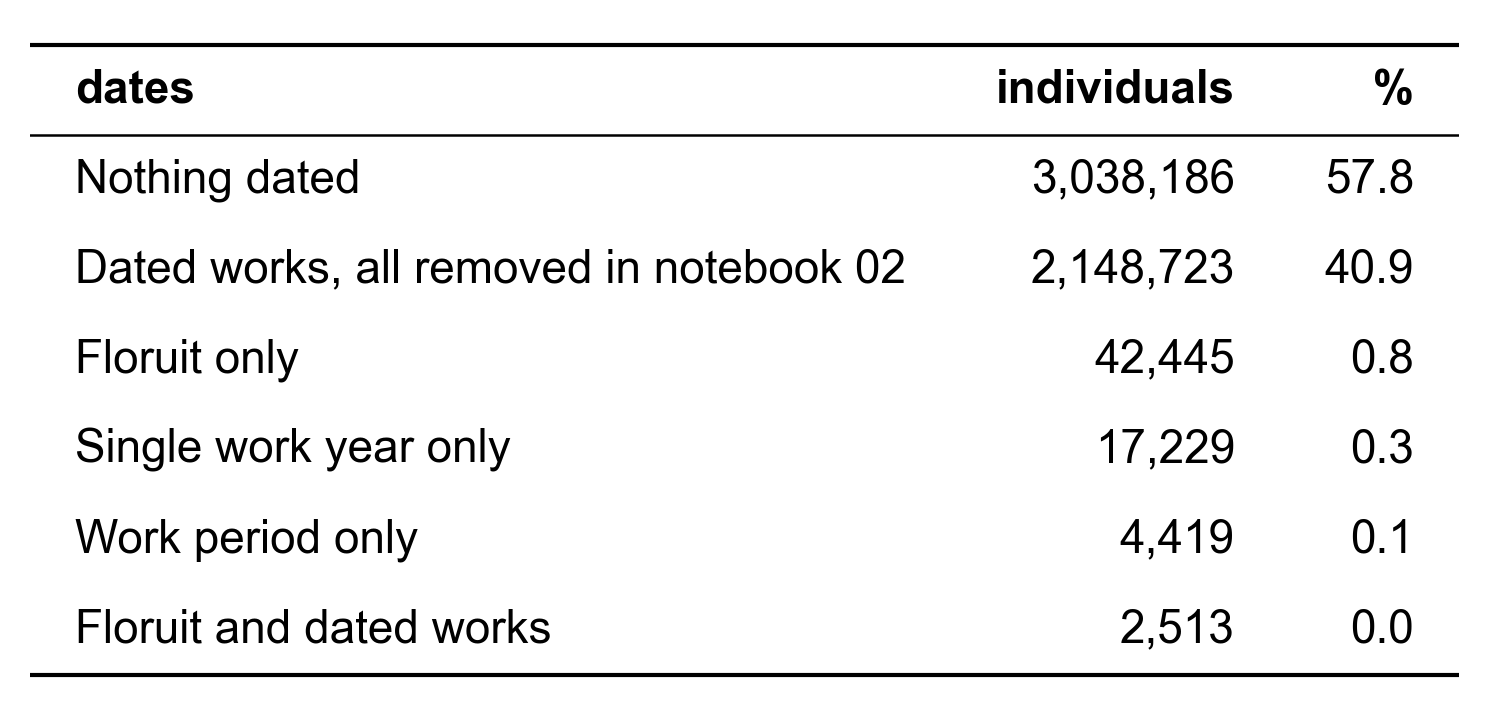

In [3]:
no_life = con.sql(f'''
    SELECT CASE
               WHEN len(individual.floruit_date) > 0 AND NOT individual.entity.qid IN ({WORKS}) THEN 'Floruit only'
               WHEN len(individual.floruit_date) > 0 THEN 'Floruit and dated works'
               WHEN {SINGLE_WORK_YEAR} THEN 'Single work year only'
               WHEN work_dates.first_work_date.source = 'dated works' THEN 'Work period only'
               WHEN individual.entity.qid IN ({WORKS}) THEN 'Dated works, all removed in notebook 02'
               ELSE 'Nothing dated'
           END AS dates,
           count(*) AS individuals
    FROM individual
    JOIN '{WORK_DATES_PATH}' AS work_dates ON work_dates.qid = individual.entity.qid
    WHERE len(individual.birth_date) = 0 AND len(individual.death_date) = 0
    GROUP BY ALL
    ORDER BY individuals DESC
''').pl()
show_table(no_life.with_columns((100 * pl.col('individuals') / pl.col('individuals').sum()).alias('%')), decimals=1)

In [4]:
floruit_only = people.filter(pl.col('no_life_dates') & pl.col('floruit_year').is_not_null() & ~pl.col('has_work_date'))
single_work = people.filter(pl.col('no_life_dates') & pl.col('floruit_year').is_null() & pl.col('single_work_year'))
assert floruit_only.height == no_life.filter(pl.col('dates') == 'Floruit only')['individuals'][0]
assert single_work.height == no_life.filter(pl.col('dates') == 'Single work year only')['individuals'][0]
print(f'{floruit_only.height:,} floruit only, {single_work.height:,} single work year only')

42,445 floruit only, 17,229 single work year only


### Precision of the floruits
In Wikidata a century-precision year names its century by its last year: 1500 is the 15th century (1401–1500) and 1501 the 16th, which the descriptions confirm ("15th-century painter" for 1500). A year ending in 50 marks the middle of the century, the only "mid-century" information the floruit value carries. The qualifier *refine date* (P4241: first half, middle of, end of…) is on about 400 of the 15,000 century floruits of Wikidata (QLever, 28 October 2026) and is not in the database.

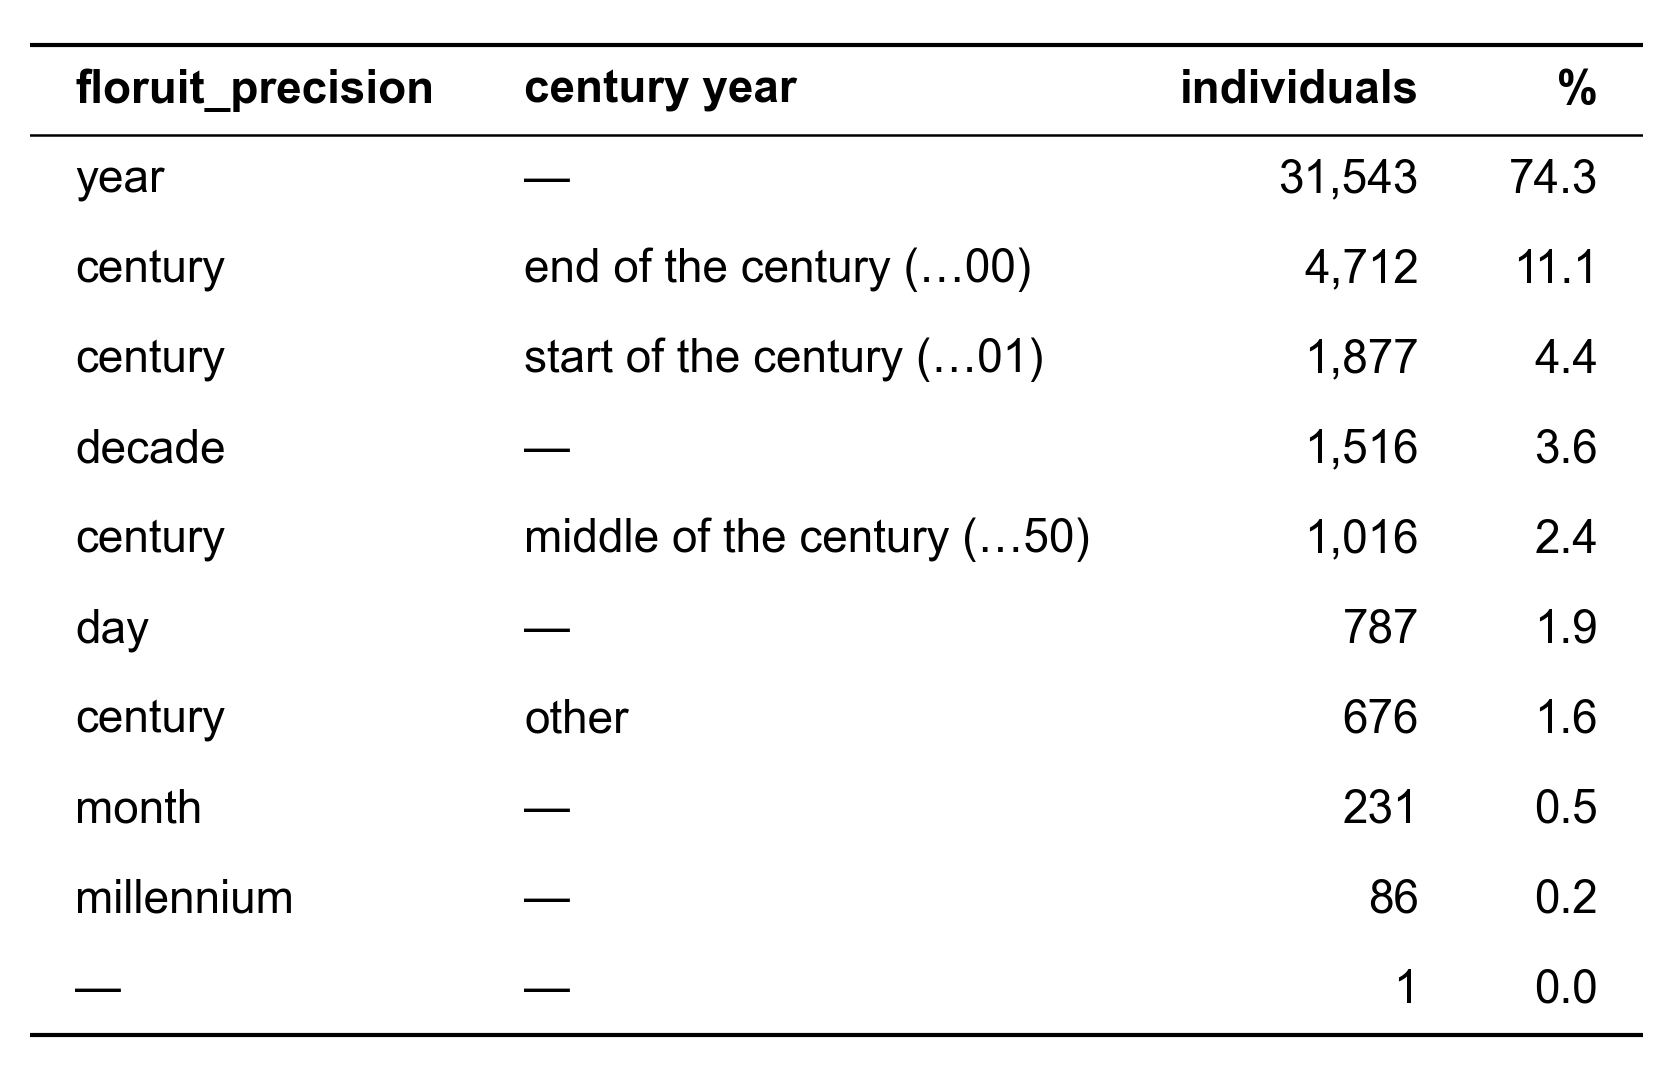

In [5]:
CENTURY_YEAR = (
    pl.when(pl.col('floruit_precision').fill_null('') != 'century').then(pl.lit(None))
    .when(pl.col('floruit_year').abs() % CENTURY == MID_CENTURY).then(pl.lit('middle of the century (…50)'))
    .when(pl.col('floruit_year').abs() % CENTURY == 0).then(pl.lit('end of the century (…00)'))
    .when(pl.col('floruit_year').abs() % CENTURY == 1).then(pl.lit('start of the century (…01)'))
    .otherwise(pl.lit('other'))
)
precision = floruit_only.group_by('floruit_precision', CENTURY_YEAR.alias('century year')).len('individuals').sort('individuals', descending=True)
show_table(precision.with_columns((100 * pl.col('individuals') / floruit_only.height).alias('%')), decimals=1)

### The year each date stands for
Day, month and year precisions keep their year; a decade counts as its middle year (1840s → 1845); a century as its middle (1500 or 1401 → 1450, 1550 → 1550, 500 BC → 450 BC). Millennium floruits are left out. A single work year keeps the year of notebook 02 (a decade there already counts as its middle year).

In [6]:
def century_middle(year):
    """The middle of the Wikidata century a year names: 1401–1500 → 1450, 1501–1600 → 1550; the same backwards before the common era."""
    end = (year.abs() + CENTURY - 1) // CENTURY * CENTURY
    return year.sign() * (end - MID_CENTURY)


def anchored(frame, year, precision, source):
    return frame.filter(precision.is_in(list(ANCHOR_PRECISIONS))).with_columns(
        pl.when(precision == 'century').then(century_middle(year))
        .when(precision == 'decade').then(year + MID_DECADE)
        .otherwise(year).cast(pl.Int64).alias('anchor_year'),
        precision.replace_strict(ANCHOR_PRECISIONS).alias('anchor_precision'),
        pl.lit(source).alias('anchor'),
    )


targets = pl.concat([
    anchored(floruit_only, pl.col('floruit_year'), pl.col('floruit_precision'), 'floruit'),
    single_work.with_columns(pl.col('work_year').alias('anchor_year'), pl.col('work_precision').alias('anchor_precision'), pl.lit('single work year').alias('anchor')),
], how='diagonal')
print(f'{floruit_only.height - targets.filter(pl.col("anchor") == "floruit").height:,} millennium floruits (or with no precision) left out')
assert century_middle(pl.Series([1500, 1401, 1501, 1550, 1600, -500, -401, -450])).to_list() == [1450, 1450, 1550, 1550, 1550, -450, -450, -450]
targets.group_by('anchor', 'anchor_precision').len('individuals').sort('anchor', 'individuals')

87 millennium floruits (or with no precision) left out


anchor,anchor_precision,individuals
str,str,u32
"""floruit""","""decade""",1516
"""floruit""","""century""",8281
"""floruit""","""year""",32561
"""single work year""","""decade""",269
"""single work year""","""year""",16960


### Main meta occupation
As in notebooks 01 and 02: the meta occupation most of the individual's occupations fall in, the first listed on a tie; All when none.

In [7]:
def main_occupation(frame):
    con.register('candidates', frame.select('qid').to_arrow())
    occupations = con.sql('''
        WITH held AS (
            SELECT individual.entity.qid AS qid, unnest(individual.occupation).entity.qid AS occupation_qid, generate_subscripts(individual.occupation, 1) AS position
            FROM individual
            JOIN candidates ON candidates.qid = individual.entity.qid
        ),
        counted AS (
            SELECT held.qid, occupation.meta_occupation AS occupation, count(*) AS occupations, min(held.position) AS first_position
            FROM held
            JOIN occupation ON occupation.entity.qid = held.occupation_qid
            WHERE list_contains($occupations, occupation.meta_occupation)
            GROUP BY ALL
        )
        SELECT qid, occupation
        FROM counted
        QUALIFY row_number() OVER (PARTITION BY qid ORDER BY occupations DESC, first_position) = 1
    ''', params={'occupations': OCCUPATIONS}).pl()
    return frame.join(occupations, on='qid', how='left').with_columns(pl.col('occupation').fill_null(ALL))


people = main_occupation(people)
targets = targets.drop('occupation', strict=False).join(people.select('qid', 'occupation'), on='qid')
targets.group_by('anchor', 'occupation').len('individuals').sort('anchor', 'individuals', descending=[False, True])

anchor,occupation,individuals
str,str,u32
"""floruit""","""Culture""",22633
"""floruit""","""All""",10862
"""floruit""","""Discovery/Science""",4451
"""floruit""","""Leadership""",4108
"""floruit""","""Sports/Games""",304
"""single work year""","""Culture""",7928
"""single work year""","""All""",6603
"""single work year""","""Discovery/Science""",2496
"""single work year""","""Leadership""",185


## Cohort ages from the parquets
The cohorts notebooks 01 and 02 estimated from, read back from their parquets: the mean age at death (01) and the median ages at the first and the last work (02) for each meta occupation and century of birth, All being everyone.

In [8]:
def parquet_cohorts(path, *columns):
    """The distinct cohorts behind the estimated dates of `columns` in a parquet."""
    union = ' UNION '.join(f'''
        SELECT DISTINCT coalesce({column}.cohort.occupation, $all) AS occupation, {column}.cohort.century AS cohort_century,
               {column}.cohort.individuals AS cohort_individuals, round({column}.cohort.age, 6) AS age
        FROM '{path}'
        WHERE {column}.source = 'estimated'
    ''' for column in columns)
    cohorts = con.sql(union, params={'all': ALL}).pl().sort('occupation', 'cohort_century')
    assert cohorts.select('occupation', 'cohort_century').is_unique().all()
    return cohorts


death_cohorts = parquet_cohorts(AGE_AT_DEATH_PATH, 'birth_date', 'death_date')
work_cohorts = parquet_cohorts(WORK_DATES_PATH, 'first_work_date').rename({'age': 'first_age'}).join(
    parquet_cohorts(WORK_DATES_PATH, 'last_work_date').select('occupation', 'cohort_century', pl.col('age').alias('last_age')),
    on=['occupation', 'cohort_century'],
)
assert work_cohorts.height == parquet_cohorts(WORK_DATES_PATH, 'last_work_date').height
everyone = work_cohorts.filter(pl.col('occupation') == ALL)
MID_WORK_AGE = ((everyone['first_age'] + everyone['last_age']) / 2 * everyone['cohort_individuals']).sum() / everyone['cohort_individuals'].sum()
print(f'{death_cohorts.height} age-at-death cohorts, {work_cohorts.height} work cohorts; age at the middle of the work period, everyone: {MID_WORK_AGE:.1f}')
work_cohorts.filter(pl.col('occupation') == ALL).with_columns((pl.col('last_age') - pl.col('first_age')).alias('work_period'))

117 age-at-death cohorts, 41 work cohorts; age at the middle of the work period, everyone: 48.2


occupation,cohort_century,cohort_individuals,first_age,last_age,work_period
str,i64,i64,f64,f64,f64
"""All""",700,14,43.0,60.5,17.5
"""All""",900,11,40.0,49.0,9.0
"""All""",1000,18,41.5,58.5,17.0
"""All""",1100,55,43.0,60.0,17.0
"""All""",1200,91,41.0,59.0,18.0
"""All""",1300,177,33.0,55.0,22.0
"""All""",1400,775,30.0,52.0,22.0
"""All""",1500,1356,30.0,53.0,23.0
"""All""",1600,2604,29.5,53.0,23.5


## Model
The floruit (or the single work year) is the middle of the work period, or the time of the major work the individual is remembered for:
1. The century of birth is first guessed as the date minus the age at the middle of the work period of everyone; the individual takes the work cohort of their occupation born in that century (the nearest century with a cohort), then, once, the cohort of the century of the birth it gives (steps 2–3).
2. First work = date − half the cohort's work period; last work = date + half of it.
3. Birth = first work − the cohort's age at first work.
4. Death = birth + the mean age at death of the occupation born in that century, no earlier than the last work; none for births after 1920.

For 1745, a work period of 20 years, a first work at 20 and death at 70: works 1735–1755, birth 1715, death 1785.

In [9]:
def nearest(frame, cohorts, century, prefix):
    """The cohort of the individual's occupation whose century of birth is nearest to `century`, the later one on a tie."""
    matched = (
        frame.select('qid', 'occupation', century.cast(pl.Int64).alias('century')).join(cohorts, on='occupation')
        .sort('qid', (pl.col('cohort_century') - pl.col('century')).abs(), 'cohort_century', descending=[False, False, True])
        .group_by('qid', maintain_order=True).first()
    )
    assert matched.height == frame.height
    return frame.join(matched.drop('occupation').rename(lambda c: c if c == 'qid' else f'{prefix}_{c}'), on='qid')


def work_period(frame, century):
    """Works = date ∓ half the work period of the cohort born in `century`, birth = first work − its age at first work."""
    frame = nearest(frame, work_cohorts, century, 'work')
    frame = frame.with_columns(((pl.col('work_last_age') - pl.col('work_first_age')) / 2).round().cast(pl.Int64).alias('half_period'))
    return frame.with_columns(
        (pl.col('anchor_year') - pl.col('half_period')).alias('first_work_year'),
        (pl.col('anchor_year') + pl.col('half_period')).alias('last_work_year'),
        (pl.col('anchor_year') - pl.col('half_period') - pl.col('work_first_age').round().cast(pl.Int64)).alias('estimated_birth_year'),
    )


def estimate(frame):
    """The work period from the guessed century of birth, again from the century of the birth it gives; death = birth + the age at death."""
    guessed = work_period(frame, (pl.col('anchor_year') - MID_WORK_AGE) // CENTURY * CENTURY)
    frame = work_period(frame, guessed['estimated_birth_year'] // CENTURY * CENTURY)
    frame = nearest(frame, death_cohorts, pl.col('estimated_birth_year') // CENTURY * CENTURY, 'death')
    from_age = pl.col('estimated_birth_year') + pl.col('death_age').round().cast(pl.Int64)
    return frame.with_columns(
        pl.when(pl.col('estimated_birth_year') <= LAST_BIRTH_YEAR).then(pl.max_horizontal(from_age, 'last_work_year')).alias('estimated_death_year'),
        (from_age < pl.col('last_work_year')).alias('death_raised'),
    )


worked = estimate(pl.DataFrame({'qid': ['example'], 'occupation': [ALL], 'anchor_year': [1745]}))
worked.select('anchor_year', 'work_cohort_century', 'work_first_age', 'work_last_age', 'estimated_birth_year', 'first_work_year', 'last_work_year', 'estimated_death_year')

anchor_year,work_cohort_century,work_first_age,work_last_age,estimated_birth_year,first_work_year,last_work_year,estimated_death_year
i64,i64,f64,f64,i64,i64,i64,i64
1745,1700,32.0,54.0,1702,1734,1756,1767


## Test on individuals with a known birth and death
Individuals with a floruit and a Wikidata birth and death precise to the year or the decade, born up to 1920: the birth and the death estimated from the floruit alone, against the true ones.

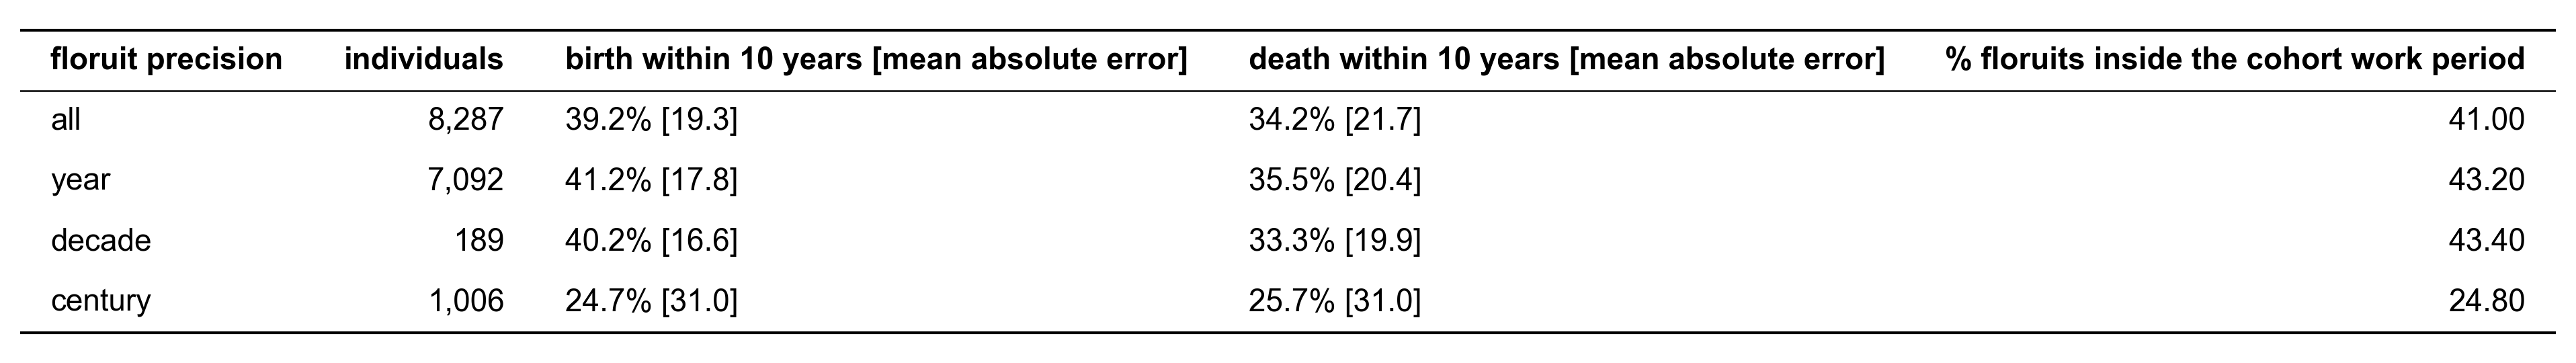

In [10]:
known = people.filter(pl.col('birth_year').is_not_null() & pl.col('death_year').is_not_null() & (pl.col('birth_year') <= LAST_BIRTH_YEAR))
known = estimate(anchored(known, pl.col('floruit_year'), pl.col('floruit_precision'), 'floruit'))
errors = known.with_columns(
    (pl.col('estimated_birth_year') - pl.col('birth_year')).abs().alias('birth_error'),
    (pl.col('estimated_death_year') - pl.col('death_year')).abs().alias('death_error'),
    ((pl.col('anchor_year') - pl.col('birth_year')).is_between(pl.col('work_first_age'), pl.col('work_last_age'))).alias('inside'),
)


def scores(frame, group):
    return {
        'floruit precision': group,
        'individuals': frame.height,
        f'birth within {WITHIN} years [mean absolute error]': f"{100 * (frame['birth_error'] <= WITHIN).mean():.1f}% [{frame['birth_error'].mean():.1f}]",
        f'death within {WITHIN} years [mean absolute error]': f"{100 * (frame['death_error'] <= WITHIN).mean():.1f}% [{frame['death_error'].mean():.1f}]",
        '% floruits inside the cohort work period': round(100 * frame['inside'].mean(), 1),
    }


show_table(pl.DataFrame([
    scores(errors, 'all'),
    *[scores(errors.filter(pl.col('anchor_precision') == p), p) for p in ['year', 'decade', 'century'] if errors.filter(pl.col('anchor_precision') == p).height],
]))

## Estimation

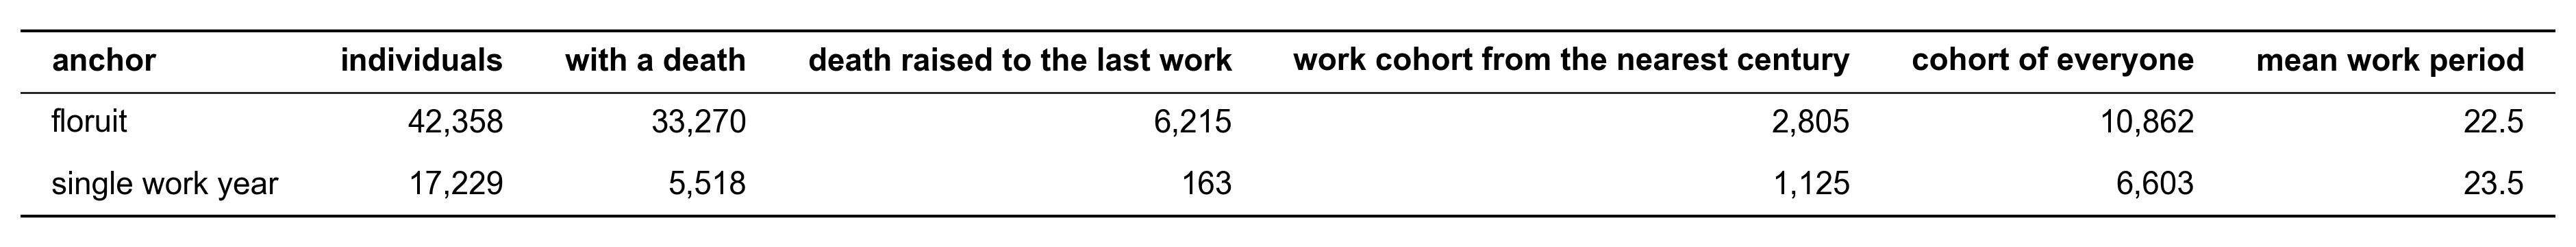

In [11]:
estimated = estimate(targets)
assert estimated.height == targets.height and estimated['estimated_birth_year'].null_count() == 0
summary = estimated.group_by('anchor').agg(
    pl.len().alias('individuals'),
    pl.col('estimated_death_year').is_not_null().sum().alias('with a death'),
    pl.col('death_raised').sum().alias('death raised to the last work'),
    (pl.col('work_cohort_century') != pl.col('work_century')).sum().alias('work cohort from the nearest century'),
    (pl.col('occupation') == ALL).sum().alias('cohort of everyone'),
    pl.col('half_period').mul(2).mean().round(1).alias('mean work period'),
).sort('anchor')
show_table(summary, decimals=1)

### Estimated dates of the best-known individuals of each group, with the cohort used

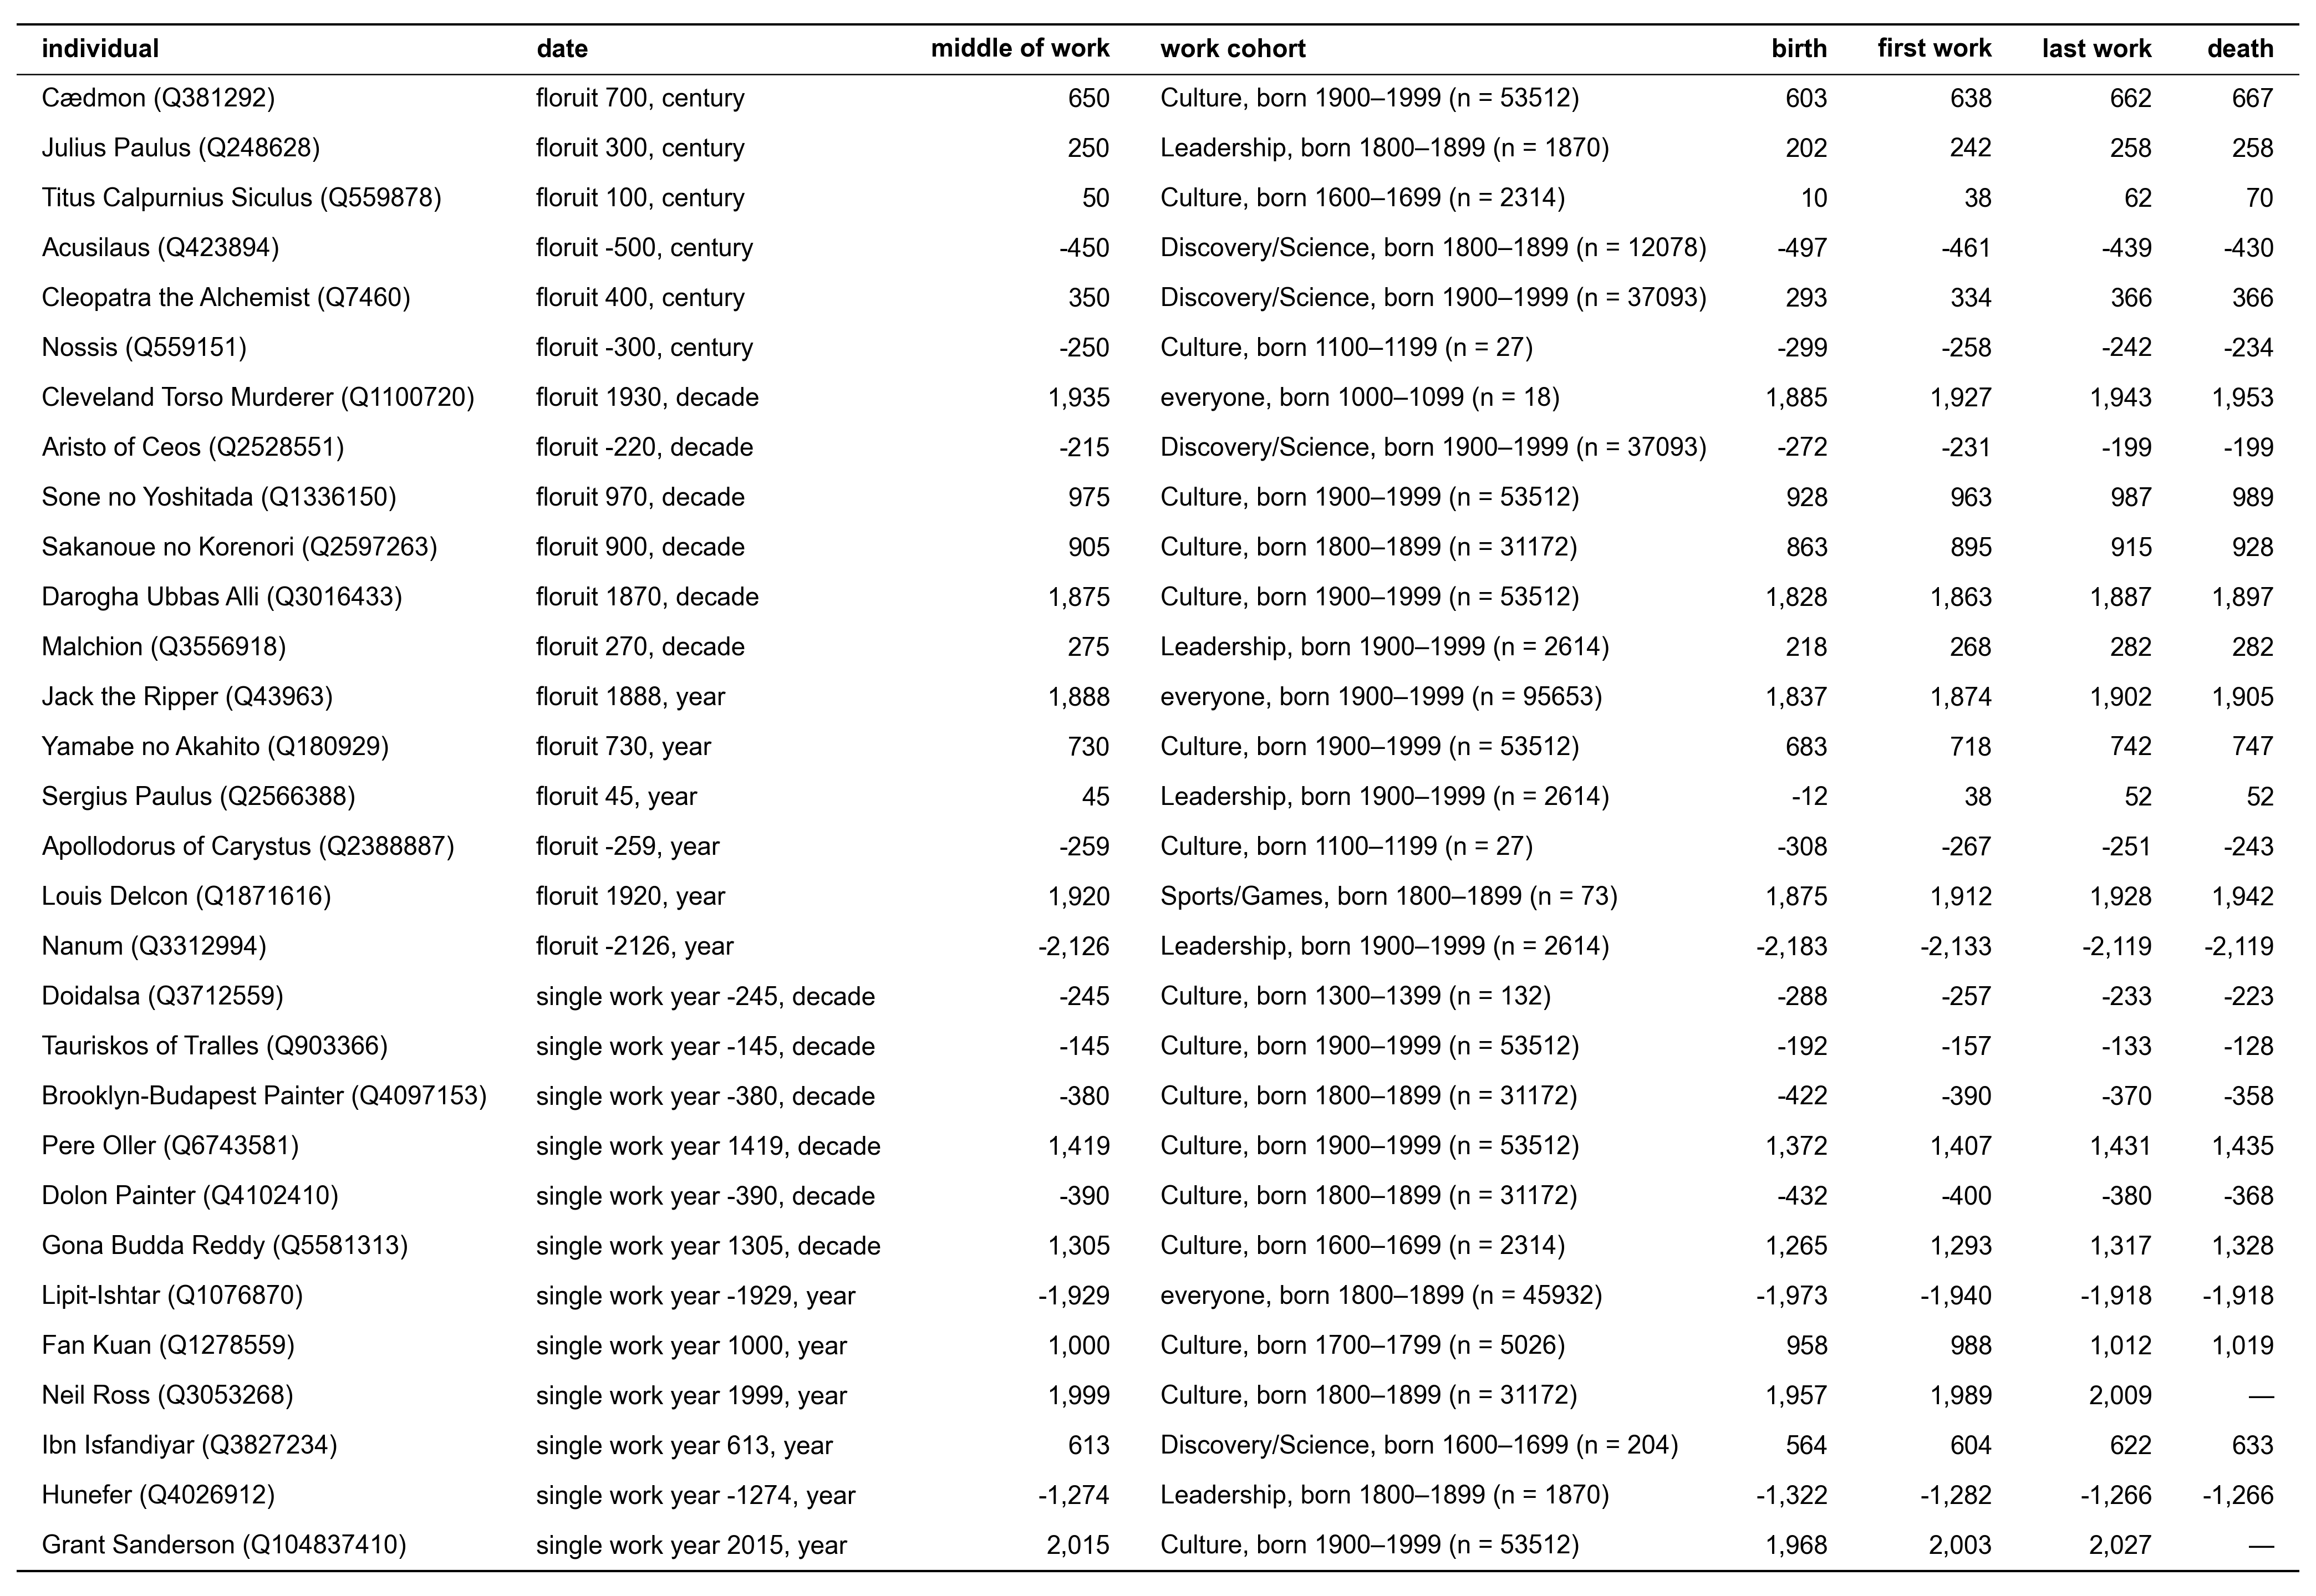

In [12]:
def cohort_label(prefix):
    group = pl.when(pl.col('occupation') == ALL).then(pl.lit('everyone')).otherwise(pl.col('occupation'))
    return pl.format('{}, born {}–{} (n = {})', group, f'{prefix}_cohort_century', pl.col(f'{prefix}_cohort_century') + CENTURY - 1, f'{prefix}_cohort_individuals')


examples = (
    estimated.join(people.select('qid', 'name', 'sitelinks'), on='qid')
    .sort('sitelinks', 'qid', descending=[True, False])
    .group_by('anchor', 'anchor_precision', maintain_order=True).head(EXAMPLES)
    .sort('anchor', 'anchor_precision', 'sitelinks', descending=[False, False, True])
)
show_table(examples.select(
    pl.format('{} ({})', 'name', 'qid').alias('individual'),
    pl.format('{} {}, {}', 'anchor', pl.coalesce(pl.col('floruit_year'), pl.col('work_year')), 'anchor_precision').alias('date'),
    pl.col('anchor_year').alias('middle of work'),
    cohort_label('work').alias('work cohort'),
    pl.col('estimated_birth_year').alias('birth'),
    pl.col('first_work_year').alias('first work'),
    pl.col('last_work_year').alias('last work'),
    pl.col('estimated_death_year').alias('death'),
))

## Save
One row per estimated individual with `IndividualEnriched.birth_date`, `death_date`, `first_work_date` and `last_work_date`, `source = 'estimated'` with the cohort used; the precision is that of the floruit or the work year (day and month → year); `field_provenance` gives the rule.

In [13]:
DATE_TYPE = duck_type(D.IndividualDate)
INPUTS = ['Individual.floruit_date', 'IndividualEnriched.first_work_date', 'IndividualEnriched.last_work_date', 'Individual.birth_date', 'Individual.death_date', 'Occupation.meta_occupation']


def group_text():
    return pl.when(pl.col('occupation') == ALL).then(pl.lit('individuals')).otherwise(pl.col('occupation') + ' individuals')


def born_text(prefix):
    return pl.format('born in {}–{}', f'{prefix}_cohort_century', pl.col(f'{prefix}_cohort_century') + CENTURY - 1)


def anchor_text():
    floruit = pl.when(pl.col('anchor_precision') == 'century').then(pl.format('the floruit {} (century precision, the middle of its century)', 'floruit_year'))
    floruit = floruit.when(pl.col('anchor_precision') == 'decade').then(pl.format('the floruit {} (decade precision, its middle year)', 'floruit_year'))
    floruit = floruit.otherwise(pl.format('the floruit {}', 'floruit_year'))
    return pl.when(pl.col('anchor') == 'floruit').then(floruit).otherwise(pl.format('the single year of the dated works {}', 'work_year'))


def work_rule(end):
    sign = '−' if end == 'first' else '+'
    return pl.format(f'Estimated from {{}}, taken as the middle of the work period: {{}} {sign} {{}} years, half the work period (median ages {{}} to {{}} at the first and the last work) of the {{}} {{}} {{}} (notebook 02).',
                     anchor_text(), 'anchor_year', 'half_period', pl.col('work_first_age').round(1), pl.col('work_last_age').round(1), 'work_cohort_individuals', group_text(), born_text('work'))


def birth_rule():
    return pl.format('Estimated from {}: the estimated first work {} − {} years, the median age at first work of the {} {} {} (notebook 02).',
                     anchor_text(), 'first_work_year', pl.col('work_first_age').round(1), 'work_cohort_individuals', group_text(), born_text('work'))


def death_rule():
    raised = pl.when(pl.col('death_raised')).then(pl.lit(', raised to the estimated last work')).otherwise(pl.lit(''))
    return pl.format('Estimated from {}: the estimated birth {} + {} years, the mean age at death of the {} {} {} (notebook 01){}.',
                     anchor_text(), 'estimated_birth_year', pl.col('death_age').round(1), 'death_cohort_individuals', group_text(), born_text('death'), raised)


def cohort(prefix, age):
    return pl.struct(
        pl.when(pl.col('occupation') != ALL).then('occupation').alias('occupation'),
        pl.col(f'{prefix}_cohort_century').alias('century'),
        pl.col(f'{prefix}_cohort_individuals').cast(pl.Int64).alias('individuals'),
        pl.col(age).cast(pl.Float64).alias('age'),
    )


dates = estimated.select(
    'qid', 'anchor_precision',
    pl.col('estimated_birth_year').alias('birth_year'), birth_rule().alias('birth_rule'), cohort('work', 'work_first_age').alias('birth_cohort'),
    pl.col('estimated_death_year').alias('death_year'), death_rule().alias('death_rule'), cohort('death', 'death_age').alias('death_cohort'),
    pl.col('first_work_year').alias('first_work_year'), work_rule('first').alias('first_work_rule'), cohort('work', 'work_first_age').alias('first_work_cohort'),
    pl.col('last_work_year').alias('last_work_year'), work_rule('last').alias('last_work_rule'), cohort('work', 'work_last_age').alias('last_work_cohort'),
)
con.register('dates', dates.to_arrow())


def estimated_date(name):
    provenance = f"{{'raw': [], 'inputs': $inputs, 'rule': dates.{name}_rule, 'ai_answer': NULL, 'retrieved_on': NULL}}"
    return f"""CASE WHEN dates.{name}_year IS NOT NULL THEN CAST({{'iso': NULL, 'year': dates.{name}_year, 'precision': dates.anchor_precision,
        'field_provenance': MAP {{'year': {provenance}, 'precision': {provenance}}}, 'source': 'estimated', 'cohort': dates.{name}_cohort}} AS {DATE_TYPE}) END AS {name}_date"""


FLORUIT_DATES = f"SELECT dates.qid, {', '.join(estimated_date(name) for name in ['birth', 'death', 'first_work', 'last_work'])} FROM dates"
con.sql(f'SELECT * FROM ({FLORUIT_DATES}) LIMIT 4', params={'inputs': INPUTS}).pl()

qid,birth_date,death_date,first_work_date,last_work_date
str,struct[6],struct[6],struct[6],struct[6]
"""Q100139581""","{null,1510,""century"",[{""year"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century): the estimated first work 1538 − 28.0 years, the median age at first work of the 2314 Culture individuals born in 1600–1699 (notebook 02)."",null,null}}, {""precision"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century): the estimated first work 1538 − 28.0 years, the median age at first work of the 2314 Culture individuals born in 1600–1699 (notebook 02)."",null,null}}],""estimated"",{""Culture"",1600,2314,28.0}}","{null,1570,""century"",[{""year"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century): the estimated birth 1510 + 60.4 years, the mean age at death of the 9794 Culture individuals born in 1500–1599 (notebook 01)."",null,null}}, {""precision"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century): the estimated birth 1510 + 60.4 years, the mean age at death of the 9794 Culture individuals born in 1500–1599 (notebook 01)."",null,null}}],""estimated"",{""Culture"",1500,9794,60.411987}}","{null,1538,""century"",[{""year"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century), taken as the middle of the work period: 1550 − 12 years, half the work period (median ages 28.0 to 52.0 at the first and the last work) of the 2314 Culture individuals born in 1600–1699 (notebook 02)."",null,null}}, {""precision"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century), taken as the middle of the work period: 1550 − 12 years, half the work period (median ages 28.0 to 52.0 at the first and the last work) of the 2314 Culture individuals born in 1600–1699 (notebook 02)."",null,null}}],""estimated"",{""Culture"",1600,2314,28.0}}","{null,1562,""century"",[{""year"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century), taken as the middle of the work period: 1550 + 12 years, half the work period (median ages 28.0 to 52.0 at the first and the last work) of the 2314 Culture individuals born in 1600–1699 (notebook 02)."",null,null}}, {""precision"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1501 (century precision, the middle of its century), taken as the middle of the work period: 1550 + 12 years, half the work period (median ages 28.0 to 52.0 at the first and the last work) of the 2314 Culture individuals born in 1600–1699 (notebook 02)."",null,null}}],""estimated"",{""Culture"",1600,2314,52.0}}"
"""Q100144584""","{null,1441,""year"",[{""year"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1490: the estimated first work 1482 − 41.0 years, the median age at first work of the 27 Culture individuals born in 1100–1199 (notebook 02)."",null,null}}, {""precision"",{[],[""Individual.floruit_date"", ""IndividualEnriched.first_work_date"", … ""Occupation.meta_occupation""],""Estimated from the floruit 1490: the estimated first work

In [14]:
if SAVE:
    OUTPUT_PATH.parent.mkdir(exist_ok=True)
    con.execute(f"COPY ({FLORUIT_DATES} ORDER BY qid) TO '{OUTPUT_PATH}' (FORMAT parquet)", {'inputs': INPUTS})
    saved = con.sql(f"SELECT count(*) AS individuals, count(birth_date) AS births, count(death_date) AS deaths, count(first_work_date) AS first_works, count(last_work_date) AS last_works FROM '{OUTPUT_PATH}'").pl()
    assert saved['individuals'][0] == saved['births'][0] == saved['first_works'][0] == estimated.height
    display(saved)

individuals,births,deaths,first_works,last_works
i64,i64,i64,i64,i64
59587,59587,38788,59587,59587
